In [1]:
########################################################
###################### Importierte Packete #############
########################################################

##### Visualisieren
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
import matplotlib.cm as cm
from matplotlib.colors import rgb2hex

##### Calculations and mathematical functions
import numpy as np

##### Data Management
import pandas as pd

##### Scientific functions
import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.general.plotting import Convert_cm_To_inch

In [3]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 50 # number of colour points taken from the colour gradient with equal distance
from scientific_utils.general.plotting import my_colormap
colormap = my_colormap.resampled(number_of_colorpoints) # was: plt.get_cmap('coolwarm', number_of_colorpoints)
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [4]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 16),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [5]:
#########################################################
##################### Start of the code ##################
#########################################################

########## Path of the folder with the measurement files ##########
path = './data/raw' #The input data is in the folder given by path
print('-------------------')
print('The following Path is selected:', path)
print('-------------------')

-------------------
The following Path is selected: ./data/raw
-------------------


In [6]:
########## Handling of the raw data ##########
#############################################

########## List all files in a directory using scandir() ##########

########## Walking a directory tree and printing the names of the directories and files ########## (only for an overview)
#print('-------------------')
#print('The Following folder and File Structure in the given path is found')
#for foldername, subfolders, filenames in os.walk(path):
#    print(f'Found directory: {foldername}')
#    for file_name in filenames:
#        print(file_name)
#print('-------------------')


########## All files and Directories given as a Dataframe ##########
dataframe_of_allfiles = pd.DataFrame(list(os.walk(path)))  # First column: directory/path ; second column: directories in the given directory/path ; third column: files in the given directory/path
                                              # os.walk('path') returns triples (dirpath, dirnames, files) -> list(os.walk('.')) puts these triples in a list


########## Sort the found files by name ##########
FilterbyName1 = 'BO first 2 s sputtering'


print('-------------------')
print('Only Files with the following Name are considered:', FilterbyName1)
print('-------------------')

list_of_filenames = dataframe_of_allfiles[2][0]

########## Sorting the battery files ##########
list_of_Measurements = sorted([k for k in list_of_filenames if FilterbyName1 in k])

########## Filter by the wanted file format ##########
Format = 'txt'
print('-------------------')
print('Only Files in the Lists with the following Format are considered:', Format)
print('-------------------')

for i in range(len(list_of_Measurements)):
    list_of_Measurements = [i for i in list_of_Measurements if i.endswith(Format)]
print(len(list_of_Measurements))

-------------------
Only Files with the following Name are considered: BO first 2 s sputtering
-------------------
-------------------
Only Files in the Lists with the following Format are considered: txt
-------------------
1


[           X      Y  Intensity
0        0.0    0.0      -0.75
1        1.0    0.0       2.75
2        2.0    0.0       6.50
3        3.0    0.0       4.75
4        4.0    0.0       0.75
...      ...    ...        ...
65531  251.0  255.0       8.50
65532  252.0  255.0       3.25
65533  253.0  255.0       6.75
65534  254.0  255.0       4.25
65535  255.0  255.0       9.00

[65536 rows x 3 columns]]
X


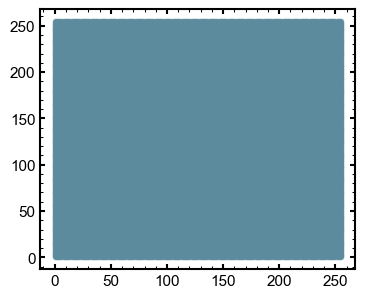

In [7]:
########## Read the files into dataframes ##########

##### read the file
data_complete = []
for i in range(len(list_of_Measurements)):
    count = -1
    with open(os.path.join(path, list_of_Measurements[i]), 'r', encoding='unicode_escape') as infile:
        for line in infile:
            count += 1
            if line.startswith("X"):
                break
    file = pd.read_csv(os.path.join(path, list_of_Measurements[i]), sep=r'\s+', encoding='unicode_escape', skiprows=count, decimal='.', dtype=np.float64)
    data_complete.append(file)
print(data_complete)    

print(data_complete[0].columns[0])

for i in range(1, len(data_complete[0].columns)-1):
    column_name = data_complete[0].columns[i]
    plt.plot(data_complete[0]['X'], data_complete[0][column_name], linestyle='None', alpha=0.5, marker='.', linewidth=1.5)


In [8]:
########## Split the steps into separate dataframes #########
#data_complete_sorted = []
#step_groupcondition = (data_complete[0]['X'] < (data_complete[0]['X'].shift() - 2)).cumsum() # if the value of the row is smaller than the value of the row before minus 0.3, one is added, otherwise the value is 0
#grouped_steps = data_complete[0].groupby(step_groupcondition)              # groups the dataframe with the results from before: a new dataframe is created for every number in 'group_ids'
#data_complete_sorted = [g for k,g in grouped_steps] # puts the separated cycles in a list, so that every list entry is one cycle

#print(data_complete_sorted[0])


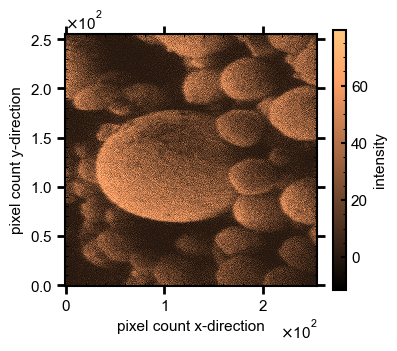

In [9]:
# https://stackoverflow.com/questions/33942700/plotting-a-heat-map-from-three-lists-x-y-intensity
x = data_complete[0]['X'].to_numpy()
y = data_complete[0]['Y'].to_numpy()
z = data_complete[0]['Intensity'].to_numpy()

x=np.unique(x)
y=np.unique(y)
X,Y = np.meshgrid(x,y)

Z=z.reshape(len(y),len(x))




fig = plt.figure()
#fig.set_size_inches(cm2inch(8, 4))
plt.rcParams.update(pgf_with_latex)

frame = fig.add_axes((.1,.3,1.0,0.6))

#number_of_points = 
cmap = plt.get_cmap('copper')

plt.pcolormesh(X,Y,Z, cmap=cmap)
plt.colorbar(label='intensity')

# Scientific label format changing from 1e1 to 1x10^1 (alternativ method: https://stackoverflow.com/questions/31517156/adjust-exponent-text-after-setting-scientific-limits-on-matplotlib-axis)
mf = matplotlib.ticker.ScalarFormatter(useMathText=True)
mf.set_powerlimits((-2,2))
frame.yaxis.set_major_formatter(mf)
frame.xaxis.set_major_formatter(mf)

frame.set_aspect('equal', 'box')
frame.tick_params(direction='out', length=6, width=2, colors='k',
               grid_color='r', grid_alpha=0.5)

# Defining the axis
frame.set_ylabel('pixel count y-direction')                 # Label of the y axis
#frame.set_ylim(Ymin_extended, Ymax_extended)                                                             # minimum and maximum value shown on the y axis
#frame.set_yticks(np.arange(0, 1.5, 0.25))                                        # which values are shown on the y axis
    
frame.set_xlabel('pixel count x-direction')                                              # Label of the x axis
#frame.set_xscale('log')
#frame.set_xlim(Xmin_extended, Xmax_extended)                                                         # minimum and maximum value shown on the x axis
#frame.set_xticks([])                               # which values are shown on the x axis
    
# Saving otpions
plt.savefig('./%s.png' %(FilterbyName1))
    
    
plot = plt.show(block=False)